# Preliminary PM2.5 Modelling Prototype: Earlwood, 2016

**Student:** Melina (Student 1: Wildfire Smoke Impact Prediction)  
**Status:** Preliminary proof of concept.

Reproducible daily PM2.5 modelling workflow using
one monitoring location and one year of air-quality data. It includes: data
quality checks, daily aggregation, calendar-accurate lag features, chronological
evaluation, baseline models, Linear Regression, and Random Forest.

It does not yet include wildfire-specific predictors such as
satellite fire hotspots, Fire Radiative Power, smoke-transport indicators, or
bushfire-specific PM2.5.

In [36]:
!pip -q install xlrd

In [2]:
import pandas as pd

file_path = "/content/Earlwood-2016.xls"

raw = pd.read_excel(file_path, header=None)

raw.head(10)

WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,Hourly Averages Time Range: 01/01/2016 00:00 t...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Initial Data,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EARLWOOD OZONE 1h average,NaN,NaN,NaN,NaN,NaN,EARLWOOD CO 1h average
2,Date,Time,EARLWOOD WDR 1h average [°],EARLWOOD TEMP 1h average [°C],EARLWOOD WSP 1h average [m/s],EARLWOOD NO 1h average [pphm],EARLWOOD NO2 1h average [pphm],EARLWOOD CO 1h average [ppm],EARLWOOD OZONE 1h average [pphm],EARLWOOD OZONE 8h rolling average [pphm],EARLWOOD PM10 1h average [µg/m³],EARLWOOD PM2.5 1h average [µg/m³],EARLWOOD HUMID 1h average [%],EARLWOOD NEPH 1h average [bsp],EARLWOOD SD1 1h average [°],EARLWOOD CO 8h rolling average [ppm]
3,01/01/2016,01:00,256.9,18.7,0.2,0.9,0.9,NaN,0,NaN,22.7,28.9,83.4,0.5,59.11,NaN
4,01/01/2016,02:00,242.7,18,0.1,NaN,NaN,NaN,NaN,NaN,40,31.2,88.6,1.35,73.36,NaN
5,01/01/2016,03:00,282,17.8,0.2,2,0.6,NaN,0.1,NaN,50.8,18.7,90.6,1.82,31.49,NaN
6,01/01/2016,04:00,271.2,17.4,0.2,1.7,0.6,NaN,0,NaN,34.9,6.1,92.2,1.23,74.28,NaN
7,01/01/2016,05:00,293.8,16.9,0.2,2.6,0.5,NaN,0,NaN,25.9,4.2,93.9,0.82,50.19,NaN
8,01/01/2016,06:00,286.8,17.1,0.4,3.3,0.5,NaN,0,NaN,26.6,NaN,94.4,0.69,28.36,NaN
9,01/01/2016,07:00,281.8,19.8,1,1.4,0.7,NaN,0.5,NaN,25,NaN,79.2,0.67,29.34,NaN


In [3]:
df = pd.read_excel(
    "/content/Earlwood-2016.xls",
    header=2
)

df.head()

WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero


,Date,Time,EARLWOOD WDR 1h average [°],EARLWOOD TEMP 1h average [°C],EARLWOOD WSP 1h average [m/s],EARLWOOD NO 1h average [pphm],EARLWOOD NO2 1h average [pphm],EARLWOOD CO 1h average [ppm],EARLWOOD OZONE 1h average [pphm],EARLWOOD OZONE 8h rolling average [pphm],EARLWOOD PM10 1h average [µg/m³],EARLWOOD PM2.5 1h average [µg/m³],EARLWOOD HUMID 1h average [%],EARLWOOD NEPH 1h average [bsp],EARLWOOD SD1 1h average [°],EARLWOOD CO 8h rolling average [ppm]
0,01/01/2016,01:00,256.9,18.7,0.2,0.9,0.9,NaN,0.0,NaN,22.7,28.9,83.4,0.50,59.11,NaN
1,01/01/2016,02:00,242.7,18.0,0.1,NaN,NaN,NaN,NaN,NaN,40.0,31.2,88.6,1.35,73.36,NaN
2,01/01/2016,03:00,282.0,17.8,0.2,2.0,0.6,NaN,0.1,NaN,50.8,18.7,90.6,1.82,31.49,NaN
3,01/01/2016,04:00,271.2,17.4,0.2,1.7,0.6,NaN,0.0,NaN,34.9,6.1,92.2,1.23,74.28,NaN
4,01/01/2016,05:00,293.8,16.9,0.2,2.6,0.5,NaN,0.0,NaN,25.9,4.2,93.9,0.82,50.19,NaN


In [4]:
clean = df[[
    "Date",
    "Time",
    "EARLWOOD WDR 1h average [°]",
    "EARLWOOD TEMP 1h average [°C]",
    "EARLWOOD WSP 1h average [m/s]",
    "EARLWOOD PM10 1h average [µg/m³]",
    "EARLWOOD PM2.5 1h average [µg/m³]",
    "EARLWOOD HUMID 1h average [%]"
]].copy()

clean.columns = [
    "date",
    "time",
    "wind_direction",
    "temperature_c",
    "wind_speed_ms",
    "pm10_ug_m3",
    "pm25_ug_m3",
    "humidity_pct"
]

clean.head()

,date,time,wind_direction,temperature_c,wind_speed_ms,pm10_ug_m3,pm25_ug_m3,humidity_pct
0,01/01/2016,01:00,256.9,18.7,0.2,22.7,28.9,83.4
1,01/01/2016,02:00,242.7,18.0,0.1,40.0,31.2,88.6
2,01/01/2016,03:00,282.0,17.8,0.2,50.8,18.7,90.6
3,01/01/2016,04:00,271.2,17.4,0.2,34.9,6.1,92.2
4,01/01/2016,05:00,293.8,16.9,0.2,25.9,4.2,93.9


In [5]:
clean["datetime"] = pd.to_datetime(
    clean["date"] + " " + clean["time"],
    format="%d/%m/%Y %H:%M",
    errors="coerce"
)

clean[["date", "time", "datetime"]].head()

,date,time,datetime
0,01/01/2016,01:00,2016-01-01 01:00:00
1,01/01/2016,02:00,2016-01-01 02:00:00
2,01/01/2016,03:00,2016-01-01 03:00:00
3,01/01/2016,04:00,2016-01-01 04:00:00
4,01/01/2016,05:00,2016-01-01 05:00:00


In [6]:
clean["day"] = clean["datetime"].dt.date

clean[["datetime", "day", "pm25_ug_m3"]].head()

,datetime,day,pm25_ug_m3
0,2016-01-01 01:00:00,2016-01-01,28.9
1,2016-01-01 02:00:00,2016-01-01,31.2
2,2016-01-01 03:00:00,2016-01-01,18.7
3,2016-01-01 04:00:00,2016-01-01,6.1
4,2016-01-01 05:00:00,2016-01-01,4.2


In [7]:
daily = (
    clean.groupby("day", as_index=False)
    .agg(
        pm25_daily_mean=("pm25_ug_m3", "mean"),
        pm10_daily_mean=("pm10_ug_m3", "mean"),
        temperature_daily_mean=("temperature_c", "mean"),
        wind_speed_daily_mean=("wind_speed_ms", "mean"),
        humidity_daily_mean=("humidity_pct", "mean"),
        valid_pm25_hours=("pm25_ug_m3", "count")
    )
)

daily.head()

,day,pm25_daily_mean,pm10_daily_mean,temperature_daily_mean,wind_speed_daily_mean,humidity_daily_mean,valid_pm25_hours
0,2016-01-01,20.643750,20.630435,21.473913,1.139130,70.139130,16
1,2016-01-02,11.687500,17.147826,21.247826,0.695652,70.391304,16
2,2016-01-03,12.205882,16.047826,21.652174,1.291304,70.304348,17
3,2016-01-04,12.957143,20.217391,20.665217,1.365217,80.126087,7
4,2016-01-05,5.972727,19.328571,19.260870,1.408696,86.195652,11


In [8]:
daily["valid_pm25_hours"].describe()

,valid_pm25_hours
count,366.000000
mean,21.797814
std,2.805590
min,0.000000
25%,22.000000
50%,23.000000
75%,23.000000
max,23.000000


In [9]:
daily["valid_pm25_hours"].value_counts().sort_index()

,count
valid_pm25_hours,
0,1
1,1
7,1
8,1
9,1
10,2
11,2
13,1
16,6


In [10]:
daily_valid = daily[daily["valid_pm25_hours"] >= 18].copy()

print("Days before filtering:", len(daily))
print("Days after filtering:", len(daily_valid))
print("Days removed:", len(daily) - len(daily_valid))

daily_valid.head()

Days before filtering: 366
Days after filtering: 348
Days removed: 18


,day,pm25_daily_mean,pm10_daily_mean,temperature_daily_mean,wind_speed_daily_mean,humidity_daily_mean,valid_pm25_hours
5,2016-01-06,3.943478,13.926087,17.682609,1.378261,93.478261,23
6,2016-01-07,5.769565,14.721739,19.669565,2.534783,74.143478,23
7,2016-01-08,6.347826,17.247826,20.326087,1.047826,68.439130,23
8,2016-01-09,8.626087,21.669565,21.743478,0.791304,70.847826,23
9,2016-01-10,6.673913,16.969565,22.434783,1.391304,75.843478,23


In [11]:
daily_valid["day"] = pd.to_datetime(daily_valid["day"])

daily_valid["month"] = daily_valid["day"].dt.month
daily_valid["day_of_year"] = daily_valid["day"].dt.dayofyear
daily_valid["day_of_week"] = daily_valid["day"].dt.dayofweek

daily_valid.head()

,day,pm25_daily_mean,pm10_daily_mean,temperature_daily_mean,wind_speed_daily_mean,humidity_daily_mean,valid_pm25_hours,month,day_of_year,day_of_week
5,2016-01-06,3.943478,13.926087,17.682609,1.378261,93.478261,23,1,6,2
6,2016-01-07,5.769565,14.721739,19.669565,2.534783,74.143478,23,1,7,3
7,2016-01-08,6.347826,17.247826,20.326087,1.047826,68.439130,23,1,8,4
8,2016-01-09,8.626087,21.669565,21.743478,0.791304,70.847826,23,1,9,5
9,2016-01-10,6.673913,16.969565,22.434783,1.391304,75.843478,23,1,10,6


In [12]:
daily_valid = daily_valid.sort_values("day").reset_index(drop=True)

print("First date:", daily_valid["day"].min())
print("Last date:", daily_valid["day"].max())
print("Number of retained days:", len(daily_valid))

daily_valid[["day", "pm25_daily_mean"]].tail()

First date: 2016-01-06 00:00:00
Last date: 2016-12-31 00:00:00
Number of retained days: 348


,day,pm25_daily_mean
343,2016-12-27,9.804348
344,2016-12-28,7.491304
345,2016-12-29,9.872727
346,2016-12-30,11.869565
347,2016-12-31,10.334783


In [13]:
all_dates = pd.date_range(
    start=daily_valid["day"].min(),
    end=daily_valid["day"].max(),
    freq="D"
)

missing_dates = all_dates.difference(daily_valid["day"])

print("Expected calendar days:", len(all_dates))
print("Available valid days:", len(daily_valid))
print("Missing calendar days:", len(missing_dates))

missing_dates[:20]

Expected calendar days: 361
Available valid days: 348
Missing calendar days: 13


DatetimeIndex(['2016-01-29', '2016-03-03', '2016-03-04', '2016-03-17',
               '2016-03-18', '2016-04-25', '2016-05-01', '2016-07-12',
               '2016-07-23', '2016-07-24', '2016-07-25', '2016-11-14',
               '2016-11-18'],
              dtype='datetime64[ns]', freq=None)

In [14]:
daily_model = daily_valid.copy()

for lag in [1, 2, 7]:
    lagged = daily_valid[["day", "pm25_daily_mean"]].copy()
    lagged["day"] = lagged["day"] + pd.Timedelta(days=lag)
    lagged = lagged.rename(
        columns={"pm25_daily_mean": f"pm25_lag_{lag}"}
    )

    daily_model = daily_model.merge(lagged, on="day", how="left")

daily_model[[
    "day",
    "pm25_daily_mean",
    "pm25_lag_1",
    "pm25_lag_2",
    "pm25_lag_7"
]].head(12)

,day,pm25_daily_mean,pm25_lag_1,pm25_lag_2,pm25_lag_7
0,2016-01-06,3.943478,NaN,NaN,NaN
1,2016-01-07,5.769565,3.943478,NaN,NaN
2,2016-01-08,6.347826,5.769565,3.943478,NaN
3,2016-01-09,8.626087,6.347826,5.769565,NaN
4,2016-01-10,6.673913,8.626087,6.347826,NaN
5,2016-01-11,12.039130,6.673913,8.626087,NaN
6,2016-01-12,16.452174,12.039130,6.673913,NaN
7,2016-01-13,8.843478,16.452174,12.039130,3.943478
8,2016-01-14,13.181818,8.843478,16.452174,5.769565
9,2016-01-15,6.665217,13.181818,8.843478,6.347826


In [15]:
model_data = daily_model.dropna(
    subset=["pm25_lag_1", "pm25_lag_2", "pm25_lag_7"]
).copy()

print("Rows before removing missing lags:", len(daily_model))
print("Rows ready for modelling:", len(model_data))
print("Rows removed:", len(daily_model) - len(model_data))

model_data[[
    "day",
    "pm25_daily_mean",
    "pm25_lag_1",
    "pm25_lag_2",
    "pm25_lag_7"
]].head()

Rows before removing missing lags: 348
Rows ready for modelling: 311
Rows removed: 37


,day,pm25_daily_mean,pm25_lag_1,pm25_lag_2,pm25_lag_7
7,2016-01-13,8.843478,16.452174,12.039130,3.943478
8,2016-01-14,13.181818,8.843478,16.452174,5.769565
9,2016-01-15,6.665217,13.181818,8.843478,6.347826
10,2016-01-16,2.077273,6.665217,13.181818,8.626087
11,2016-01-17,2.661905,2.077273,6.665217,6.673913


In [16]:
feature_cols = [
    "pm10_daily_mean",
    "temperature_daily_mean",
    "wind_speed_daily_mean",
    "humidity_daily_mean",
    "month",
    "day_of_year",
    "day_of_week",
    "pm25_lag_1",
    "pm25_lag_2",
    "pm25_lag_7"
]

target_col = "pm25_daily_mean"

split_index = int(len(model_data) * 0.80)

train = model_data.iloc[:split_index].copy()
test = model_data.iloc[split_index:].copy()

X_train = train[feature_cols]
y_train = train[target_col]

X_test = test[feature_cols]
y_test = test[target_col]

print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Training period:", train["day"].min(), "to", train["day"].max())
print("Testing period:", test["day"].min(), "to", test["day"].max())

Training rows: 248
Testing rows: 63
Training period: 2016-01-13 00:00:00 to 2016-10-21 00:00:00
Testing period: 2016-10-22 00:00:00 to 2016-12-31 00:00:00


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

baseline_pred = test["pm25_lag_1"]

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print(f"Baseline MAE: {baseline_mae:.3f} µg/m³")
print(f"Baseline RMSE: {baseline_rmse:.3f} µg/m³")

Baseline MAE: 2.448 µg/m³
Baseline RMSE: 3.208 µg/m³


In [18]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=500,
    max_depth=8,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print(f"Random Forest MAE: {rf_mae:.3f} µg/m³")
print(f"Random Forest RMSE: {rf_rmse:.3f} µg/m³")
print(f"MAE improvement vs baseline: {baseline_mae - rf_mae:.3f} µg/m³")

Random Forest MAE: 3.521 µg/m³
Random Forest RMSE: 4.232 µg/m³
MAE improvement vs baseline: -1.073 µg/m³


In [19]:
from sklearn.dummy import DummyRegressor

mean_model = DummyRegressor(strategy="mean")
mean_model.fit(X_train, y_train)

mean_pred = mean_model.predict(X_test)

mean_mae = mean_absolute_error(y_test, mean_pred)
mean_rmse = np.sqrt(mean_squared_error(y_test, mean_pred))

print(f"Mean baseline MAE: {mean_mae:.3f} µg/m³")
print(f"Mean baseline RMSE: {mean_rmse:.3f} µg/m³")
print(f"Training-set mean PM2.5: {y_train.mean():.3f} µg/m³")

Mean baseline MAE: 2.155 µg/m³
Mean baseline RMSE: 2.684 µg/m³
Training-set mean PM2.5: 8.002 µg/m³


In [21]:
print("Missing values in training features:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

print("\nMissing values in testing features:")
print(X_test.isna().sum()[X_test.isna().sum() > 0])

Missing values in training features:
pm10_daily_mean    1
dtype: int64

Missing values in testing features:
Series([], dtype: int64)


In [22]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train_imputed, y_train)

linear_pred = linear_model.predict(X_test_imputed)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))

print(f"Linear Regression MAE: {linear_mae:.3f} µg/m³")
print(f"Linear Regression RMSE: {linear_rmse:.3f} µg/m³")
print(f"MAE improvement vs mean baseline: {mean_mae - linear_mae:.3f} µg/m³")

Linear Regression MAE: 2.637 µg/m³
Linear Regression RMSE: 3.122 µg/m³
MAE improvement vs mean baseline: -0.483 µg/m³


In [23]:
results = pd.DataFrame({
    "Model": [
        "Mean baseline",
        "Persistence baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE (µg/m³)": [
        mean_mae,
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE (µg/m³)": [
        mean_rmse,
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ]
}).sort_values("MAE (µg/m³)").reset_index(drop=True)

results

,Model,MAE (µg/m³),RMSE (µg/m³)
0,Mean baseline,2.154984,2.684125
1,Persistence baseline,2.447777,3.207876
2,Linear Regression,2.637491,3.121792
3,Random Forest,3.520726,4.231573


In [24]:
prediction_results = test[["day", "pm25_daily_mean"]].copy()

prediction_results["mean_baseline"] = mean_pred
prediction_results["persistence_baseline"] = baseline_pred.values
prediction_results["linear_regression"] = linear_pred
prediction_results["random_forest"] = rf_pred

prediction_results["mean_abs_error"] = (
    prediction_results["pm25_daily_mean"]
    - prediction_results["mean_baseline"]
).abs()

prediction_results.head(10)

,day,pm25_daily_mean,mean_baseline,persistence_baseline,linear_regression,random_forest,mean_abs_error
279,2016-10-22,3.940909,8.002023,15.552174,5.143203,5.006322,4.061114
280,2016-10-23,3.009524,8.002023,3.940909,6.675957,5.209666,4.992500
281,2016-10-24,3.965217,8.002023,3.009524,6.436974,6.367705,4.036806
282,2016-10-25,9.736364,8.002023,3.965217,10.781774,9.687465,1.734340
283,2016-10-26,7.739130,8.002023,9.736364,10.929431,13.107943,0.262893
284,2016-10-27,8.595455,8.002023,7.739130,11.448123,11.295948,0.593431
285,2016-10-28,4.565217,8.002023,8.595455,10.563854,10.228477,3.436806
286,2016-10-29,6.957143,8.002023,4.565217,6.417410,5.965031,1.044881
287,2016-10-30,8.408696,8.002023,6.957143,5.961590,5.959245,0.406672
288,2016-10-31,4.300000,8.002023,8.408696,3.567789,3.917030,3.702023


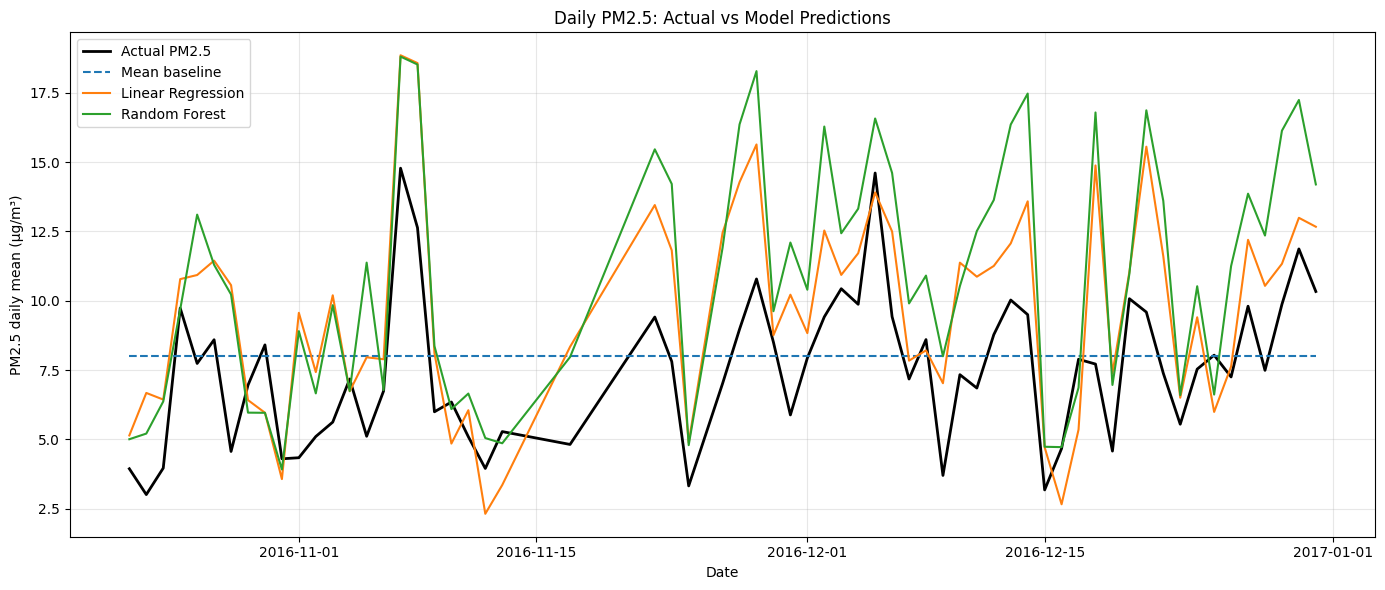

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    prediction_results["day"],
    prediction_results["pm25_daily_mean"],
    label="Actual PM2.5",
    color="black",
    linewidth=2
)

plt.plot(
    prediction_results["day"],
    prediction_results["mean_baseline"],
    label="Mean baseline",
    linestyle="--",
    color="tab:blue"
)

plt.plot(
    prediction_results["day"],
    prediction_results["linear_regression"],
    label="Linear Regression",
    color="tab:orange"
)

plt.plot(
    prediction_results["day"],
    prediction_results["random_forest"],
    label="Random Forest",
    color="tab:green"
)

plt.title("Daily PM2.5: Actual vs Model Predictions")
plt.xlabel("Date")
plt.ylabel("PM2.5 daily mean (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()